# 07 — Model Comparison, Ensembles, Ablations, and Generalization

**Goal.** Compare all six saved models on the untouched test set, verify that metrics are reproducible, evaluate simple ensembles, quantify the leakage effect of `Original_Purchase_Price_INR`, test generalization to unseen car models and future model years, check the Delhi-NCR penalty, and select the dashboard winner.

The test set is used only for final evaluation and comparison. All tuning and refitting used train/validation data only.


In [1]:
from pathlib import Path
import sys, warnings, json
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, data, metrics, plots, training, comparison

plots.set_style()
FIGURES_DIR = config.ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Loaded comparison helpers | seed={config.SEED}")

Loaded comparison helpers | seed=42


## 1. Load data, test split, and saved metrics

The canonical split indices ensure the comparison uses exactly the same test rows as notebooks 01–06.

In [2]:
raw = data.load_raw_data()
data.validate_data(raw)
train, val, test = data.split_frames(raw)
saved_metrics = training.load_metrics()
print('Saved model keys:', sorted(k for k in saved_metrics if k in config.MODEL_NAMES))

{
  "rows": 500000,
  "columns": 17,
  "null_counts": {},
  "duplicate_car_ids": 0,
  "duplicate_full_rows": 0,
  "non_positive_resale_prices": 0,
  "resale_ge_original": 0,
  "ev_nonzero_cc": 0,
  "non_ev_zero_cc": 0,
  "purchase_before_manufacture": 0,
  "impossible_fuel_transmission": 0,
  "impossible_combos": [],
  "valid": true,
  "issues": []
}


Split sizes -> train: 350,000 | val: 75,000 | test: 75,000
Saved model keys: ['catboost', 'lightgbm', 'mlp', 'random_forest', 'ridge', 'xgboost']


## 2. Recompute test predictions and verify metrics.json

Each saved pipeline is reloaded and evaluated independently. Any mismatch with `metrics.json` raises an error before the analysis proceeds.

In [3]:
pred_frame, recomputed = comparison.recompute_test_predictions(config.MODEL_NAMES, test)
check = comparison.assert_metrics_match(recomputed, saved_metrics)
display(check[check['Metric'].isin(['r2_log', 'rmse_log', 'mape'])].pivot(index='Model', columns='Metric', values='abs_diff'))
print('Maximum absolute difference:', float(check['abs_diff'].max()))
pred_frame.to_parquet(config.TEST_PREDICTIONS_PATH, index=False)
print('Saved test predictions to', config.TEST_PREDICTIONS_PATH)

Metric,mape,r2_log,rmse_log
Model,,,
catboost,0.000000e+00,0.0,0.0
lightgbm,0.000000e+00,0.0,0.0
mlp,0.000000e+00,0.0,0.0
random_forest,1.776357e-15,0.0,0.0
ridge,0.000000e+00,0.0,0.0
xgboost,0.000000e+00,0.0,0.0


Maximum absolute difference: 2.1827872842550278e-11
Saved test predictions to /home/b/Documents/used-car-price-predictor/artifacts/test_predictions.parquet


## 3. Leaderboard

Lower log-RMSE, MAE, RMSE, MAPE, and median APE are better; higher log-R² is better. The best value per metric is highlighted.

In [4]:
leaderboard = comparison.leaderboard(pred_frame, saved_metrics)
display(
    leaderboard.drop(columns=['key']).style
    .format({'r2_log': '{:.5f}', 'rmse_log': '{:.5f}', 'mae_inr': '₹{:,.0f}',
             'rmse_inr': '₹{:,.0f}', 'mape': '{:.2f}%', 'median_ape': '{:.2f}%',
             'train_time_s': '{:.1f}s', 'inference_ms_per_1k': '{:.2f}ms', 'size_mb': '{:.2f}MB'})
    .highlight_min(subset=['rmse_log', 'mae_inr', 'rmse_inr', 'mape', 'median_ape'], color='#d4edda')
    .highlight_max(subset=['r2_log'], color='#d4edda')
)

,Model,r2_log,rmse_log,mae_inr,rmse_inr,mape,median_ape,train_time_s,inference_ms_per_1k,size_mb
0,LightGBM,0.99775,0.05021,"₹45,167","₹95,564",3.99%,3.35%,115.8s,408.11ms,8.96MB
1,XGBoost,0.99746,0.05328,"₹47,360","₹100,281",4.22%,3.52%,169.3s,113.43ms,38.95MB
2,CatBoost,0.99722,0.05577,"₹52,591","₹128,103",4.29%,3.48%,230.6s,40.09ms,1.55MB
3,MLP,0.99593,0.06746,"₹57,406","₹120,055",5.19%,4.09%,407.3s,46.05ms,0.42MB
4,Random Forest,0.99458,0.07785,"₹63,714","₹133,306",6.02%,4.77%,204.4s,116.41ms,551.41MB
5,Ridge,0.98126,0.14479,"₹144,667","₹344,478",11.33%,9.31%,80.6s,24.57ms,0.01MB


## 4. Ensembles

The all-model and top-3 averages are computed in log space, which is a geometric mean of prices and matches the multiplicative generator.

In [5]:
all_names = list(config.MODEL_NAMES)
top3_names = leaderboard.head(3)['key'].tolist()
ensemble_all = comparison.evaluate_ensemble(pred_frame, all_names)
ensemble_top3 = comparison.evaluate_ensemble(pred_frame, top3_names)
print('All-model ensemble:', json.dumps(ensemble_all, indent=2))
print('Top-3 ensemble:', json.dumps(ensemble_top3, indent=2))
print('Top-3 members:', top3_names)
training.append_metrics('ensemble_average', {'model_label': 'Ensemble (all)', 'members': all_names, 'test': ensemble_all})
training.append_metrics('ensemble_top3', {'model_label': 'Ensemble (top-3)', 'members': top3_names, 'test': ensemble_top3})

All-model ensemble: {
  "r2_log": 0.9969744008516053,
  "rmse_log": 0.05817110744782467,
  "mae_log": 0.046008697516867585,
  "mae_inr": 53438.583844707384,
  "rmse_inr": 119344.12205537918,
  "mape": 4.6161890306725555,
  "median_ape": 3.828720107075134
}
Top-3 ensemble: {
  "r2_log": 0.9977533872194092,
  "rmse_log": 0.05012631164042703,
  "mae_log": 0.0398573097181226,
  "mae_inr": 46019.81321755869,
  "rmse_inr": 99266.18486060332,
  "mape": 3.9914297846826763,
  "median_ape": 3.355614254439009
}
Top-3 members: ['lightgbm', 'xgboost', 'catboost']


In [6]:
ensemble_table = pd.DataFrame([
    {'Ensemble': 'All 6 models', **ensemble_all},
    {'Ensemble': 'Top 3 models', **ensemble_top3},
])
display(ensemble_table.style.format({'r2_log': '{:.5f}', 'rmse_log': '{:.5f}', 'mae_inr': '₹{:,.0f}', 'rmse_inr': '₹{:,.0f}', 'mape': '{:.2f}%', 'median_ape': '{:.2f}%'}))

,Ensemble,r2_log,rmse_log,mae_log,mae_inr,rmse_inr,mape,median_ape
0,All 6 models,0.99697,0.05817,0.046009,"₹53,439","₹119,344",4.62%,3.83%
1,Top 3 models,0.99775,0.05013,0.039857,"₹46,020","₹99,266",3.99%,3.36%


## 5. Comparison plots

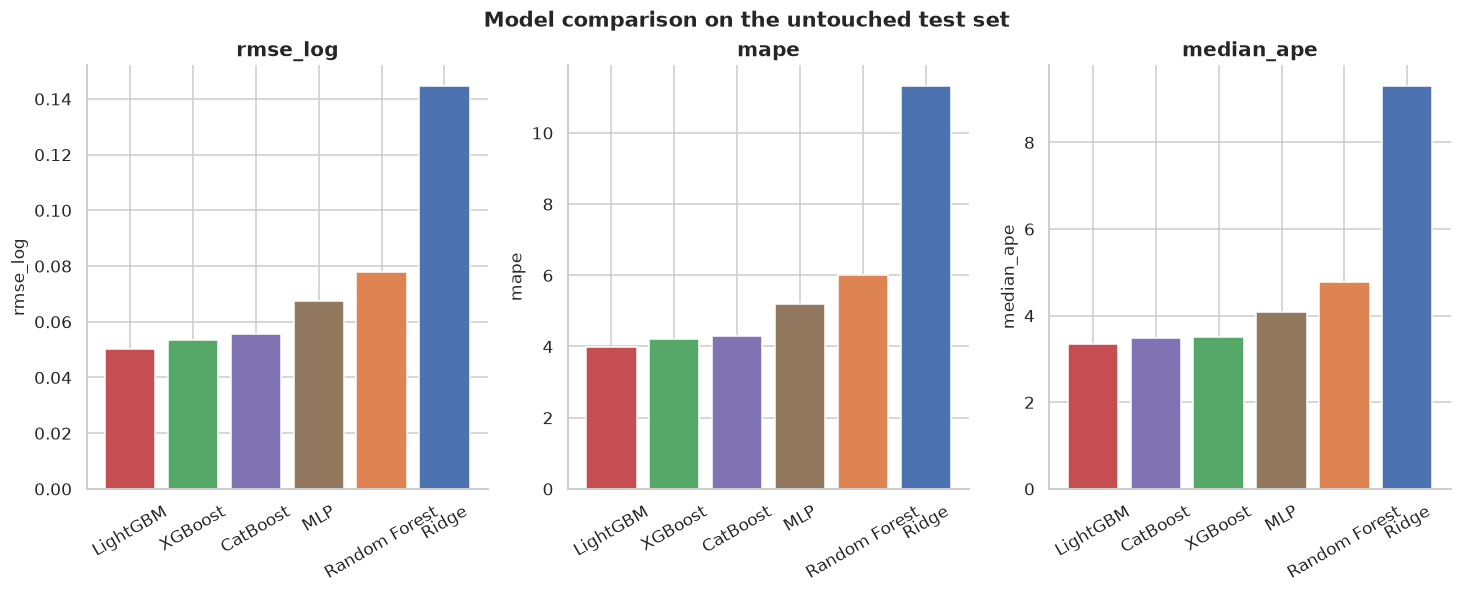

In [7]:
fig = plots.plot_metric_bars(leaderboard)
fig.savefig(FIGURES_DIR / 'comparison_metric_bars.png', dpi=110, bbox_inches='tight')
plt.show()

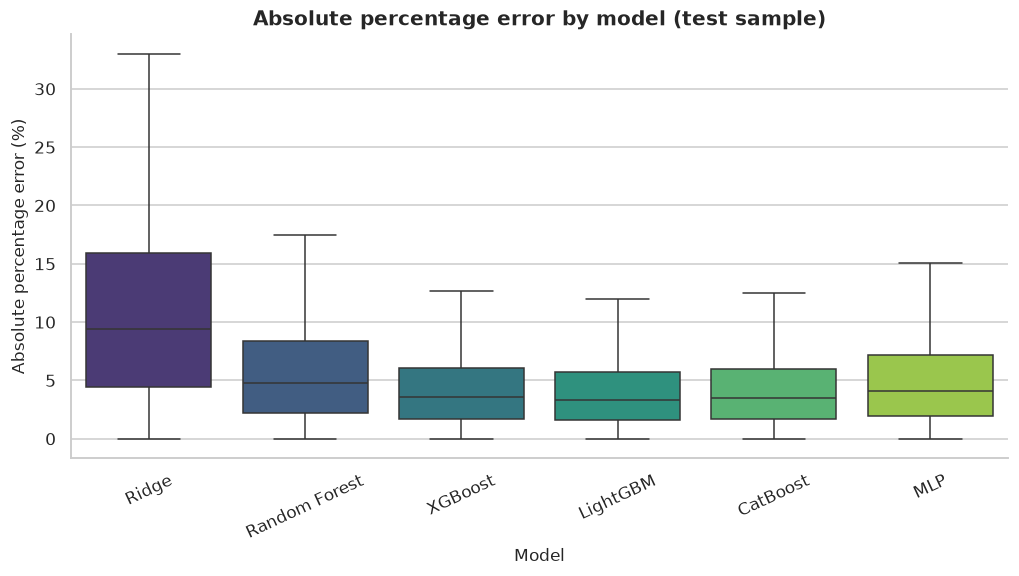

In [8]:
ape = comparison.ape_frame(pred_frame, sample_size=20_000)
fig = plots.plot_ape_box(ape, 'Absolute percentage error by model (test sample)')
fig.savefig(FIGURES_DIR / 'comparison_ape_box.png', dpi=110, bbox_inches='tight')
plt.show()

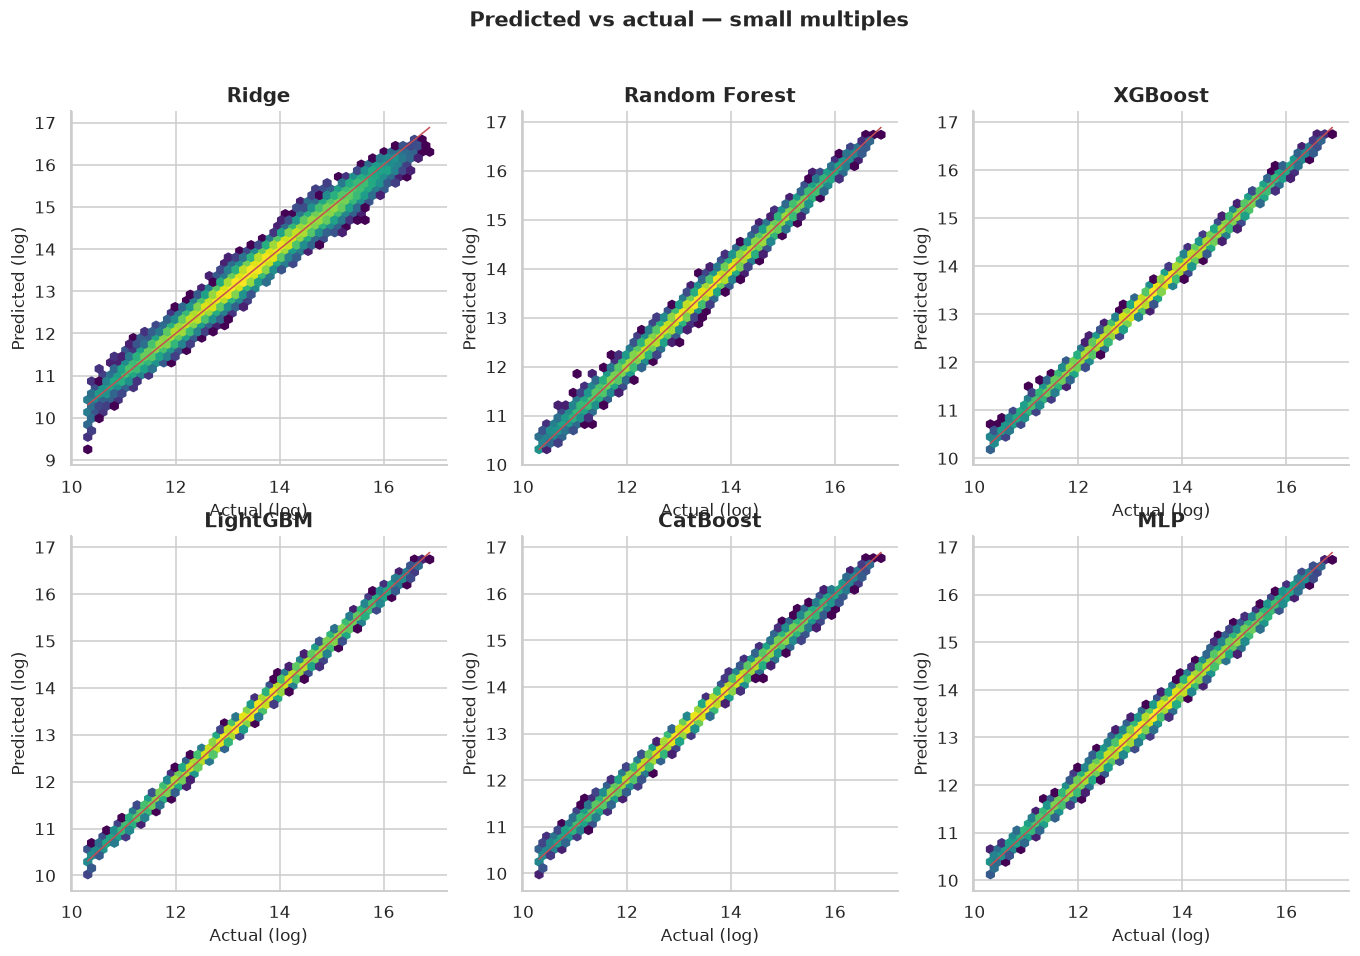

In [9]:
preds = {config.MODEL_LABELS[name]: pred_frame[name].to_numpy(float) for name in config.MODEL_NAMES}
fig = plots.plot_small_multiples(preds, pred_frame['y_true_inr'].to_numpy(float), 'Predicted vs actual — small multiples')
fig.savefig(FIGURES_DIR / 'comparison_small_multiples.png', dpi=110, bbox_inches='tight')
plt.show()

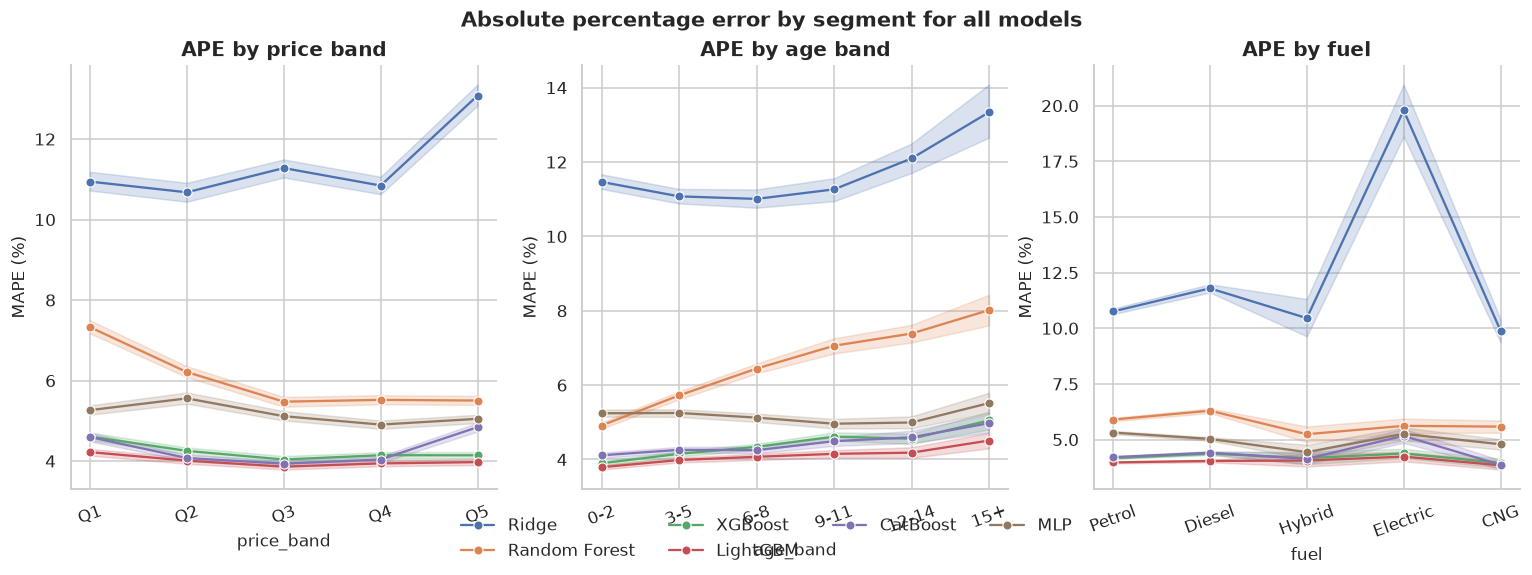

In [10]:
segments = comparison.segment_error_frame(pred_frame, test, sample_size=30_000)
fig = plots.plot_error_by_segments_all(segments)
fig.savefig(FIGURES_DIR / 'comparison_error_segments.png', dpi=110, bbox_inches='tight')
plt.show()

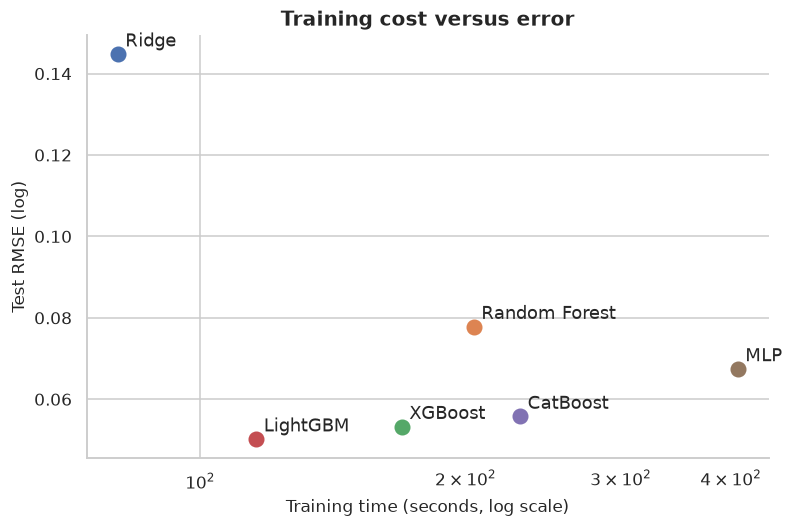

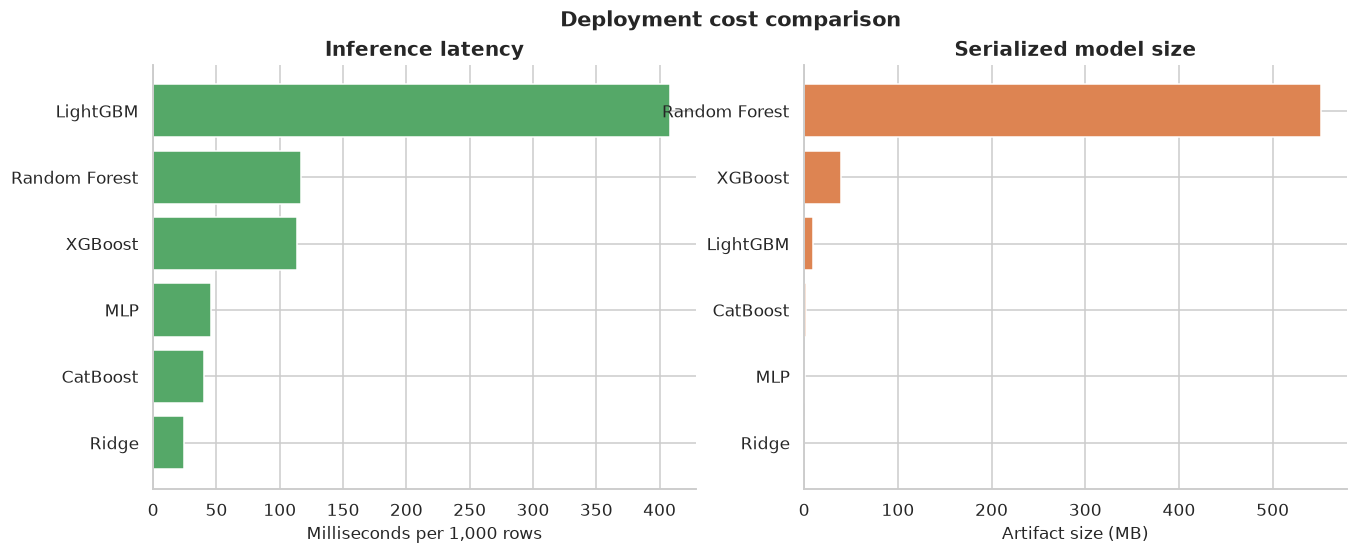

In [11]:
fig = plots.plot_train_time_vs_error(leaderboard)
fig.savefig(FIGURES_DIR / 'comparison_train_vs_error.png', dpi=110, bbox_inches='tight')
plt.show()
fig = plots.plot_time_size(leaderboard)
fig.savefig(FIGURES_DIR / 'comparison_time_size.png', dpi=110, bbox_inches='tight')
plt.show()

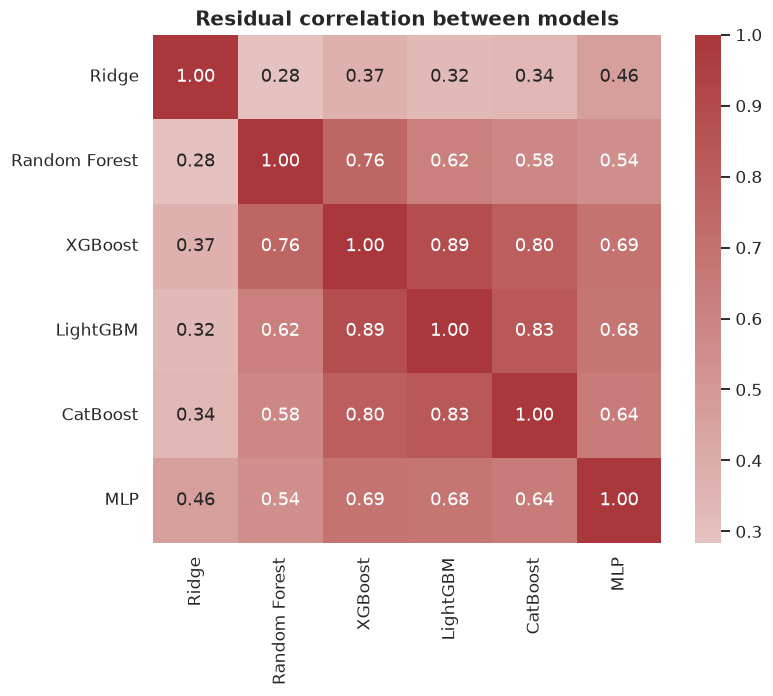

In [12]:
corr = comparison.residual_correlation(pred_frame)
fig = plots.plot_residual_correlation(corr)
fig.savefig(FIGURES_DIR / 'comparison_residual_corr.png', dpi=110, bbox_inches='tight')
plt.show()

## 6. Ablation: Original_Purchase_Price_INR

The default models exclude this generator input because real listings rarely provide it. Refitting the best model with it quantifies the leakage effect. This ablation is never eligible to become the dashboard winner.

In [13]:
best_row = comparison.choose_best(leaderboard)
best_name = str(best_row['key'])
print('Best default model:', config.MODEL_LABELS[best_name])
with open(config.params_path(best_name), encoding='utf-8') as handle:
    best_params = json.load(handle)['params']
ablation = comparison.run_ablation(best_name, best_params, train, test, best_row.to_dict())
ablation_table = pd.DataFrame([
    {'Setting': 'Without original price', 'RMSE(log)': best_row['rmse_log'], 'MAPE': best_row['mape']},
    {'Setting': 'With original price', 'RMSE(log)': ablation['test']['rmse_log'], 'MAPE': ablation['test']['mape']},
])
display(ablation_table)

Best default model: LightGBM


,Setting,RMSE(log),MAPE
0,Without original price,0.050213,3.990451
1,With original price,0.049953,3.980078


## 7. Generalization tests

(a) Hold out every training row for 15 randomly chosen car models and evaluate on their test rows. (b) Hold out `Manufacturing_Year >= 2024` from training and evaluate on 2024–2026 test rows.

In [14]:
car_deg, year_deg, holdout_models = comparison.run_generalization(train, test, pred_frame)
print('Held-out car models:', holdout_models)
display(car_deg.style.format({c: '{:.4f}' for c in ['baseline_rmse_log', 'holdout_rmse_log', 'degradation_pct', 'baseline_mape', 'holdout_mape']}))
display(year_deg.style.format({c: '{:.4f}' for c in ['baseline_rmse_log', 'holdout_rmse_log', 'degradation_pct', 'baseline_mape', 'holdout_mape']}))

Held-out car models: ['Atto 3', 'Aura', 'Range Rover Sport', 'Tavera', 'Cooper', 'Spark', 'Astor', 'i20 Active', 'Indica', 'V-Class', 'Xcent', 'Micra', 'Sunny', 'Santro', 'Yaris']


,Model,baseline_rmse_log,holdout_rmse_log,degradation_pct,baseline_mape,holdout_mape,n_holdout
0,Ridge,0.1519,0.5496,261.8155,12.8618,57.6341,2251
1,Random Forest,0.0836,0.7908,846.1666,6.4919,64.2542,2251
2,XGBoost,0.0560,0.6688,1093.8011,4.4354,53.2767,2251
3,LightGBM,0.0517,0.4349,741.8689,4.0821,41.7811,2251
4,CatBoost,0.0669,0.3225,382.0624,4.9759,25.7513,2251
5,MLP,0.0724,0.6034,733.4661,5.4602,45.3184,2251


,Model,baseline_rmse_log,holdout_rmse_log,degradation_pct,baseline_mape,holdout_mape,n_holdout
0,Ridge,0.1464,0.1921,31.2103,11.4706,15.9931,22268
1,Random Forest,0.0641,0.2527,294.0449,4.9944,18.1402,22268
2,XGBoost,0.0490,0.2322,373.5411,3.9032,16.7321,22268
3,LightGBM,0.0477,0.2195,359.9936,3.7936,16.5507,22268
4,CatBoost,0.0534,0.2148,302.0800,4.1137,15.8637,22268
5,MLP,0.0687,0.1389,102.0902,5.2571,8.4921,22268


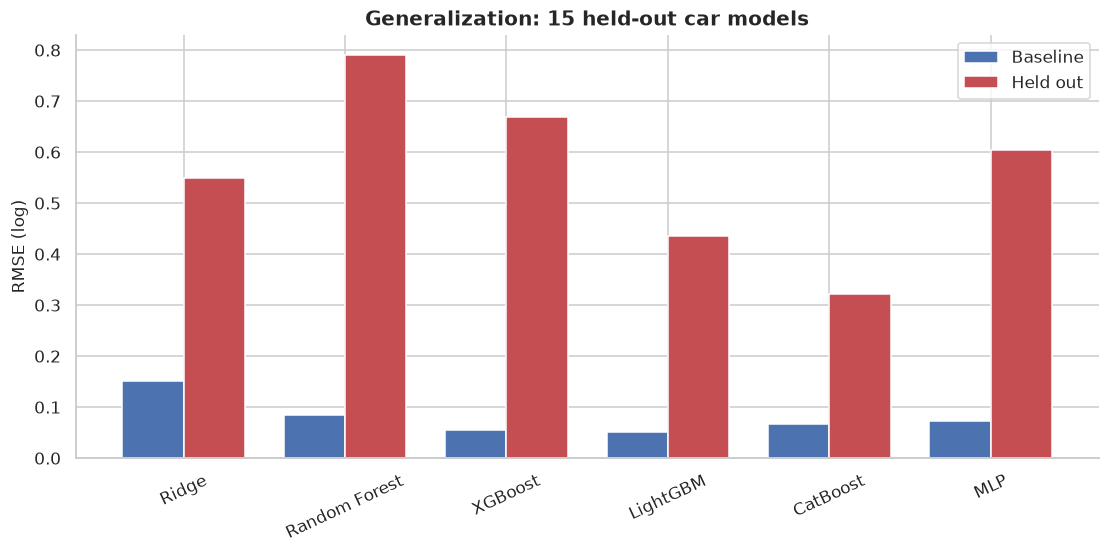

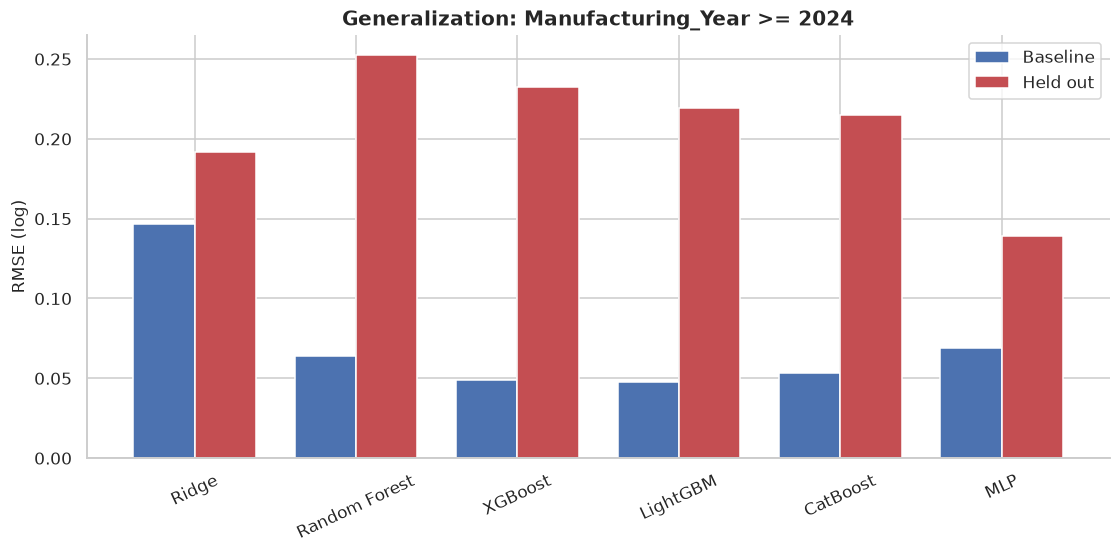

In [15]:
fig = plots.plot_generalization(car_deg, 'Generalization: 15 held-out car models')
fig.savefig(FIGURES_DIR / 'comparison_generalization_cars.png', dpi=110, bbox_inches='tight')
plt.show()
fig = plots.plot_generalization(year_deg, 'Generalization: Manufacturing_Year >= 2024')
fig.savefig(FIGURES_DIR / 'comparison_generalization_years.png', dpi=110, bbox_inches='tight')
plt.show()

## 8. Delhi-NCR restriction check

Counterfactual predictions move the same diesel car between Delhi and Pune for age 9 (not restricted) and age 11 (restricted). Actual data ratios are shown for context.

Age,9,11
Series,,
Actual data,0.961,0.434
CatBoost,0.962,0.433
LightGBM,0.946,0.426
MLP,0.940,0.430
Random Forest,0.993,0.442
Ridge,0.951,0.442
XGBoost,0.955,0.433


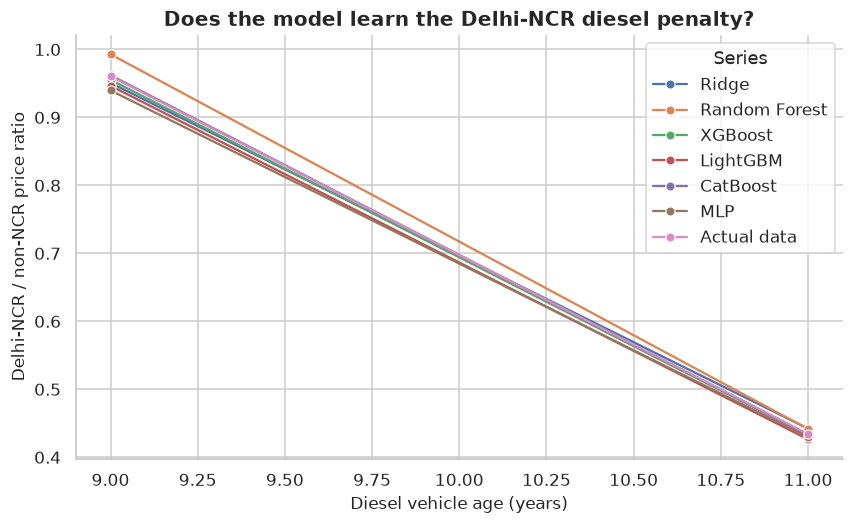

In [16]:
delhi = comparison.delhi_rule_check(test, config.MODEL_NAMES)
display(delhi.pivot(index='Series', columns='Age', values='ratio').style.format('{:.3f}'))
fig = plots.plot_delhi_rule(delhi)
fig.savefig(FIGURES_DIR / 'comparison_delhi_rule.png', dpi=110, bbox_inches='tight')
plt.show()

## 9. Paired bootstrap comparison of the top two models

A paired bootstrap resamples test rows and estimates the 95% confidence interval for the RMSE(log) difference. A CI entirely above zero means the second model is worse.

In [17]:
top2 = leaderboard.head(2)['key'].tolist()
ci = metrics.bootstrap_rmse_difference(
    pred_frame['y_true_inr'].to_numpy(float),
    pred_frame[top2[0]].to_numpy(float),
    pred_frame[top2[1]].to_numpy(float),
    n_bootstrap=2000,
)
print('Top two:', [config.MODEL_LABELS[x] for x in top2])
print(json.dumps(ci, indent=2))

Top two: ['LightGBM', 'XGBoost']
{
  "rmse_a": 0.05021319418552379,
  "rmse_b": 0.053275643626556755,
  "difference": -0.003062449441032962,
  "ci_low": -0.0032694368931408223,
  "ci_high": -0.0028527324513427945,
  "n_bootstrap": 2000,
  "probability_a_better": 1.0
}


## 10. Final recommendation and winner artifact

In [18]:
best_payload = comparison.write_best_model(best_row, ensemble_all, ensemble_top3)
print(json.dumps(best_payload, indent=2))
print('Wrote', config.BEST_MODEL_PATH)

{
  "model_name": "lightgbm",
  "model_label": "LightGBM",
  "selection_metric": "test.rmse_log",
  "test_metrics": {
    "r2_log": 0.9977455924868713,
    "rmse_log": 0.05021319418552379,
    "mae_inr": 45166.63732881433,
    "rmse_inr": 95564.09855055762,
    "mape": 3.9904513221479387,
    "median_ape": 3.352093326895879
  },
  "ensemble_average_test_metrics": {
    "r2_log": 0.9969744008516053,
    "rmse_log": 0.05817110744782467,
    "mae_log": 0.046008697516867585,
    "mae_inr": 53438.583844707384,
    "rmse_inr": 119344.12205537918,
    "mape": 4.6161890306725555,
    "median_ape": 3.828720107075134
  },
  "ensemble_top3_test_metrics": {
    "r2_log": 0.9977533872194092,
    "rmse_log": 0.05012631164042703,
    "mae_log": 0.0398573097181226,
    "mae_inr": 46019.81321755869,
    "rmse_inr": 99266.18486060332,
    "mape": 3.9914297846826763,
    "median_ape": 3.355614254439009
  },
  "generated_at": "2026-10-21T18:43:45.188293+00:00",
  "note": "Selected from the six default mod

## Findings

The leaderboard and bootstrap interval determine the winner. The all-model ensemble is reported alongside the individual models; it is available in the dashboard with any subset of models. The ablation quantifies how much the excluded original-price column would have leaked, and the generalization tables show whether performance survives unseen car models and future model years. The Delhi-NCR check verifies that the learned penalty drops between age 9 and age 11 for diesel cars. Because the data is synthetic, these results validate the pipeline and the generator's rules rather than the real used-car market.